In [1]:
import itertools
from ast import literal_eval
import os

import numpy as np
import pandas as pd
from scipy.integrate import trapezoid

import matplotlib.pyplot as plt
from matplotlib.gridspec import GridSpec
from matplotlib.ticker import MaxNLocator
from matplotlib.backends.backend_pdf import PdfPages
import seaborn as sns

from mg_sampling import PROJECT_DIR
from mg_sampling.constants import RT
from mg_sampling.tools import read_plumed, read_plumed_fes, range_to_edges, edges_to_range, finitemin, finitemax, block_analysis, read_wsv, demux
from mg_sampling.bias import bias_fn

LABELS = {
    'amber_tip3p': "Amber/TIP3P",
    'mMg_tip3p': "microMg/TIP3P",
    'nMg_tip3p': "nanoMg/TIP3P", 
    'mMg_opc': "microMg/OPC",
    'ecc_spce': "AmberECC/SPCE",
}

FORCEFIELDS_ARCHIVE = ['amber_tip3p', 'mMg_tip3p', 'nMg_tip3p', 'mMg_opc', 'ecc_spce']
FORCEFIELDS = ['mMg_tip3p']

os.makedirs('figures/replex', exist_ok=True)
os.makedirs('figures/replex/archive', exist_ok=True)

In [2]:
ff = 'mMg_tip3p'

cv = np.stack([
    read_plumed(PROJECT_DIR / f'replex/7ez0/archive/{ff}/rep{i:02d}/bias.COLVAR.{i}').drop_duplicates('time').assign(rep=i)
    for i in range(12)
])
cv_dmx = demux(cv, repindex_file=PROJECT_DIR / f'replex/7ez0/archive/{ff}/replica_index.xvg')

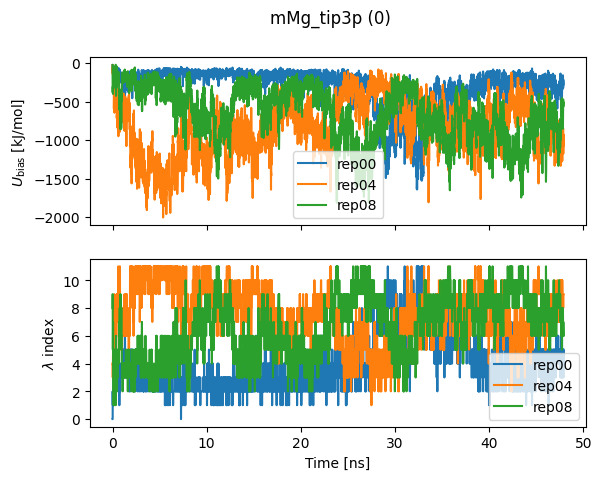

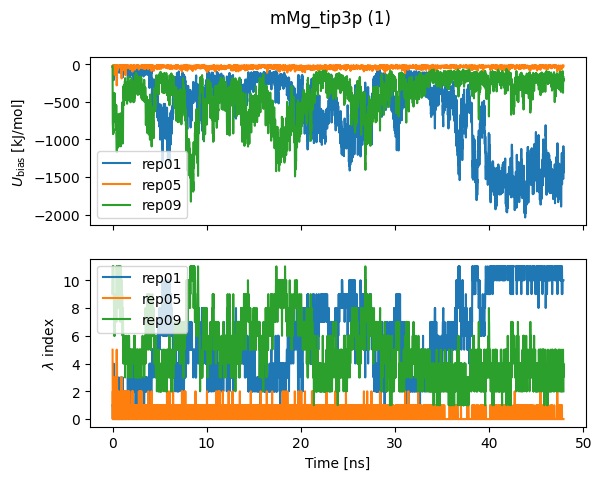

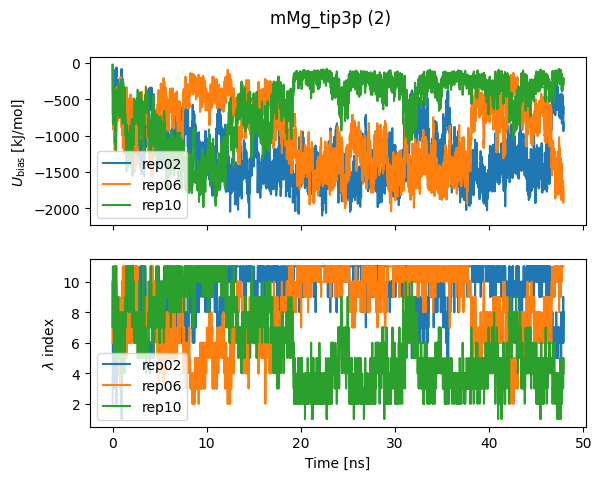

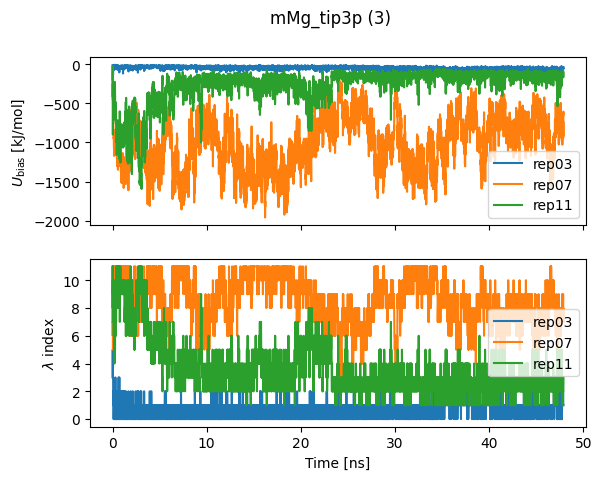

In [4]:
figs = []
for n in range(4):
    fig, axarr = plt.subplots(nrows=2, sharex=True)
    fig.suptitle(f"{ff} ({n})")
    for i in range(n, 12, 4):
        ax = axarr[0]
        ax.plot(cv_dmx[i, :, 0]/1000, cv_dmx[i, :, 1], label=f'rep{i:02d}')
        ax.set_ylabel("$U_\mathrm{bias}$ [kJ/mol]")
        ax.legend()
        ax = axarr[1]
        ax.plot(cv_dmx[i, :, 0]/1000, cv_dmx[i, :, -1], label=f'rep{i:02d}')
        ax.yaxis.set_major_locator(MaxNLocator(integer=True))
        ax.set_ylabel("$λ$ index")
        ax.set_xlabel("Time [ns]")
        ax.legend()
    figs.append(fig)

with PdfPages(f'figures/replex/archive/bias_{ff}.pdf') as pdf:
    for fig in figs:
        pdf.savefig(fig, bbox_inches='tight') 

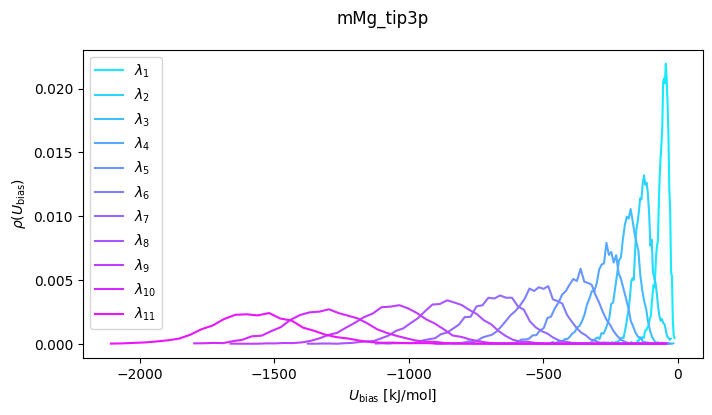

In [5]:
# Bias distribution as a function of λ
fig, ax = plt.subplots(figsize=(8, 4))
for i in range(1, 12):
    ρ_u, bins = np.histogram(cv[i, :, 1], bins=50, density=True)
    u_range = edges_to_range(bins)
    ax.plot(u_range, ρ_u, label=f'$λ_{{{i}}}$', color=plt.cm.cool(i/12.0))
ax.legend()
ax.set_xlabel('$U_\mathrm{bias}$ [kJ/mol]')
ax.set_ylabel('$ρ(U_\mathrm{bias}$)')
fig.suptitle(ff)
plt.savefig(f'figures/replex/archive/bias_dist_{ff}.pdf')

In [6]:
d_mg_op = np.stack([
    np.loadtxt(PROJECT_DIR / f'replex/7ez0/archive/{ff}/rep{i:02d}/dist_MG_O_Phosphate.xvg', comments=['@', '#'])
    for i in range(12)
])
d_op_mg = np.stack([
    np.loadtxt(PROJECT_DIR / f'replex/7ez0/archive/{ff}/rep{i:02d}/dist_O_Phosphate_MG.xvg', comments=['@', '#'])
    for i in range(12)
])

d_mg_op_dmx = demux(d_mg_op, repindex_file=PROJECT_DIR / f'replex/7ez0/archive/{ff}/replica_index.xvg')
d_op_mg_dmx = demux(d_op_mg, repindex_file=PROJECT_DIR / f'replex/7ez0/archive/{ff}/replica_index.xvg')

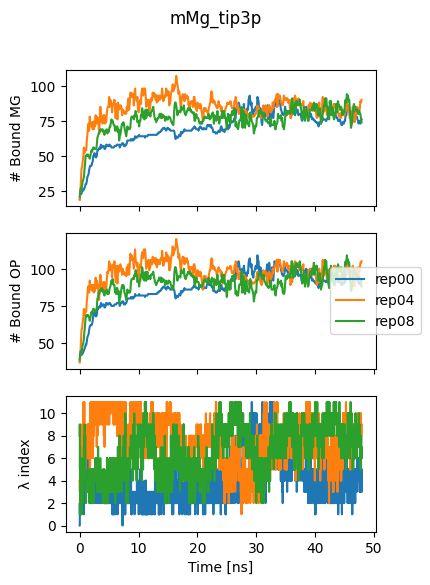

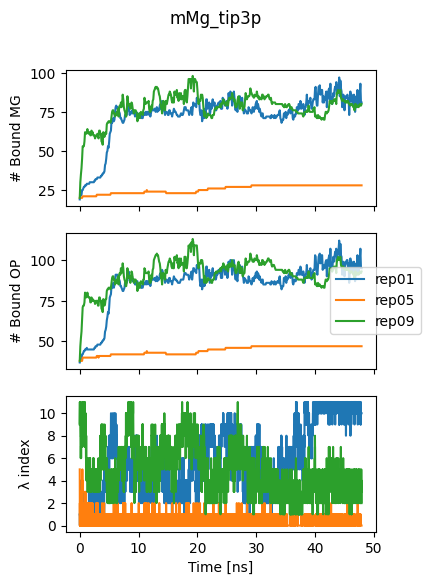

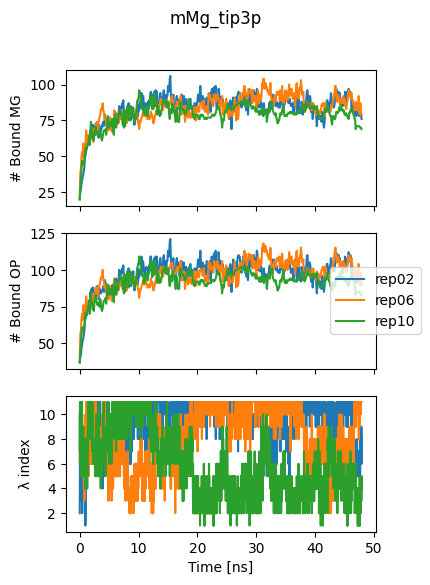

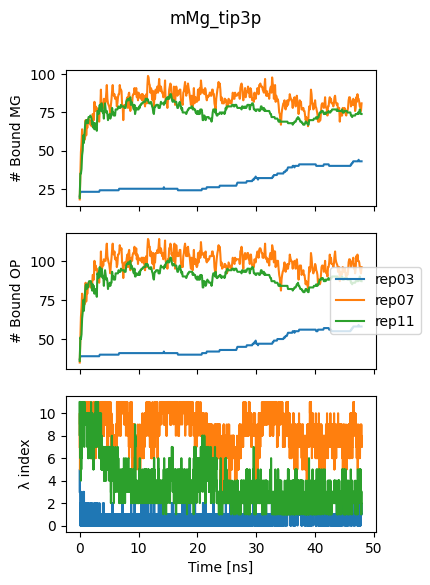

In [7]:
figs = []
for n in range(4):
    fig, axarr = plt.subplots(nrows=3, sharex=True, figsize=(4, 6))
    fig.suptitle(ff)
    for i in range(n, 12, 4):
        ax = axarr[0]
        ax.plot(d_mg_op_dmx[i, :, 0] / 1000, (d_mg_op_dmx[i, :, 1:] < 0.25).sum(axis=-1), label=f'rep{i:02d}')
        ax.set_ylabel('# Bound MG')
        ax = axarr[1]
        ax.plot(d_op_mg_dmx[i, :, 0] / 1000, (d_op_mg_dmx[i, :, 1:] < 0.25).sum(axis=-1), label=f'rep{i:02d}')
        ax.set_ylabel('# Bound OP')
        ax.legend(loc='center', bbox_to_anchor=(1, 0.5))
        ax = axarr[2]
        ax.plot(cv_dmx[i, :, 0] / 1000, cv_dmx[i, :, -1], label=f'rep{i:02d}')
        ax.yaxis.set_major_locator(MaxNLocator(integer=True))
        ax.set_ylabel('λ index')
        ax.set_xlabel("Time [ns]")
    figs.append(fig)

with PdfPages(f'figures/replex/archive/bound_mg_{ff}.pdf') as pdf:
    for fig in figs:
        pdf.savefig(fig, bbox_inches='tight') 

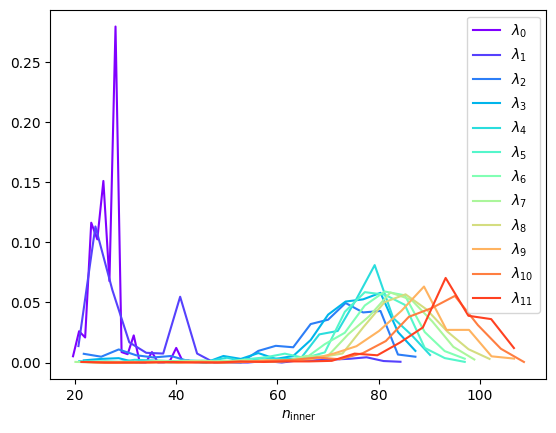

In [8]:
fig, ax = plt.subplots()
for i in range(12):
    hist, n_edges = np.histogram((d_mg_op[i, :, 1:] < 0.28).sum(axis=-1), density=True, bins=20)
    ax.plot(edges_to_range(n_edges), hist, color=plt.cm.rainbow(i/12.0), label=f"$λ_{{{i}}}$")
ax.legend()
ax.set_xlabel('$n_\mathrm{inner}$')
plt.savefig(f'figures/replex/archive/n_inner_dist_{ff}.pdf')

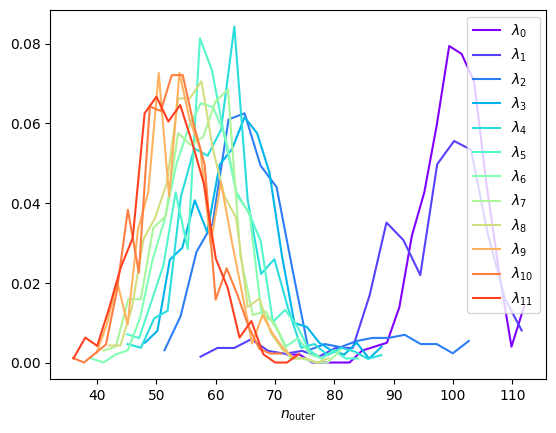

In [9]:
fig, ax = plt.subplots()
for i in range(12):
    hist, n_edges = np.histogram(((d_mg_op[i, :, 1:] > 0.28)*(d_mg_op[i, :, 1:] < 0.5)).sum(axis=-1), density=True, bins=20)
    ax.plot(edges_to_range(n_edges), hist, color=plt.cm.rainbow(i/12.0), label=f"$λ_{{{i}}}$")
ax.legend()
ax.set_xlabel('$n_\mathrm{outer}$')
plt.savefig(f'figures/replex/archive/n_outer_dist_{ff}.pdf')


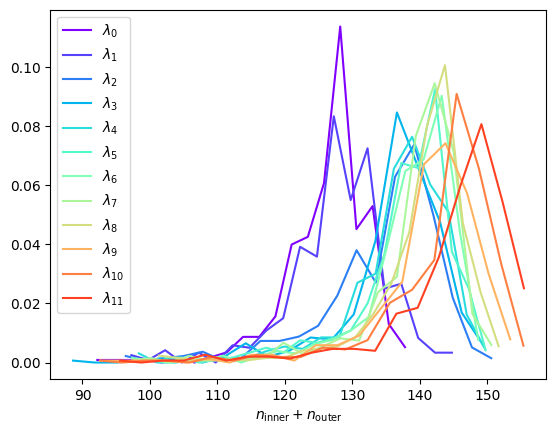

In [10]:
fig, ax = plt.subplots()
for i in range(12):
    hist, n_edges = np.histogram((d_mg_op[i, :, 1:] < 0.5).sum(axis=-1), density=True, bins=20)
    ax.plot(edges_to_range(n_edges), hist, color=plt.cm.rainbow(i/12.0), label=f"$λ_{{{i}}}$")
ax.legend()
ax.set_xlabel('$n_\mathrm{inner} + n_\mathrm{outer}$')
plt.savefig(f'figures/replex/archive/n_tot_dist_{ff}.pdf')

Text(0, 0.5, 'Frames')

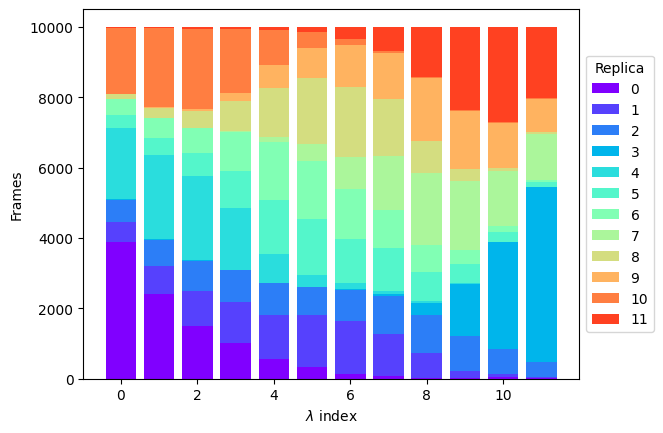

In [92]:
# Composition of each temp
fig, ax = plt.subplots()
bottom = np.zeros(12)
for k in range(12):
    n_frames = cv_dmx.shape[1]
    x, counts = np.unique(cv_dmx[k, :, -1].astype(int), return_counts=True)
    ax.bar(x, counts, bottom=bottom[x], color=plt.cm.rainbow(k/12), label=f'{k}')
    bottom[x] += counts
ax.legend(title='Replica', loc='center left', bbox_to_anchor=(1, 0.5))
ax.set_xlabel("$λ$ index")
ax.set_ylabel("Frames")

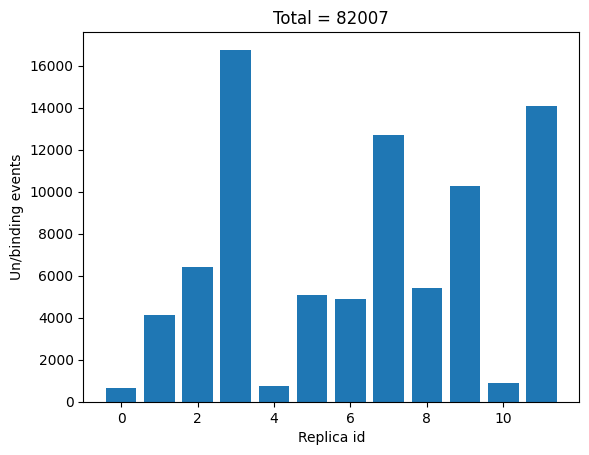

In [81]:
is_bound_mg_dmx = d_mg_op_dmx[:, :, 1:] < 0.25
events = is_bound_mg_dmx[:, 1:, :] != is_bound_mg_dmx[:, :-1, :]
fig, ax = plt.subplots()
ax.bar(range(12), events.sum(axis=-1).sum(axis=-1))
ax.set_ylabel(f"Un/binding events")
ax.set_xlabel(f"Replica id")
ax.set_title(f"Total = {events.sum()}")
plt.savefig(f'figures/replex/event_counts_{ff}.pdf')

Text(0, 0.5, '$\\min_t D_\\mathrm{Hamming}(\\vec{n}(t), \\vec{n}(t+τ))$')

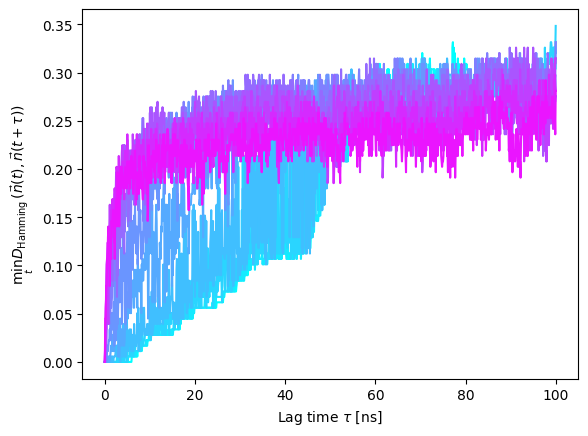

In [82]:
fig, ax = plt.subplots()
for k in range(12):
    is_bound_mg = d_mg_op[k, :, 1:] < 0.25
    N = len(is_bound_mg)
    c = []
    for τ in range(N):
        # Hamming distance at lag τ, take the minimum value on the ensemble
        c.append((is_bound_mg[:N-τ] != is_bound_mg[τ:N]).mean(axis=-1).min())

    ax.plot(np.arange(N)/10, c, color=plt.cm.cool(k / 12))
ax.set_xlabel("Lag time $τ$ [ns]")
ax.set_ylabel(r"$\min_t D_\mathrm{Hamming}(\vec{n}(t), \vec{n}(t+τ))$")

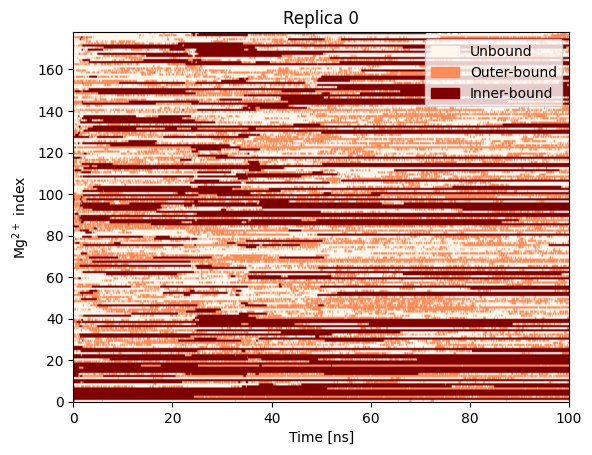

In [106]:
# New bound ions configurations found
k = 0
fig, ax = plt.subplots()
is_bound_mg = (d_mg_op_dmx[k, :, 1:] < 0.25) * 1 + (d_mg_op_dmx[k, :, 1:] < 0.42) * 1
from matplotlib.patches import Patch
cmap = plt.cm.OrRd
custom_patches = [Patch(color=cmap(0.), label='Unbound'),
                Patch(color=cmap(.5), label='Outer-bound'),
                Patch(color=cmap(1.), label='Inner-bound')]
ax.imshow(is_bound_mg.T, origin='lower', extent=[0, len(is_bound_mg)/10, 0, is_bound_mg.shape[1]], aspect='auto', cmap=cmap)
ax.set_xlabel("Time [ns]")
ax.set_ylabel(r"Mg$^{2+}$ index")
ax.set_title(f"Replica {k}")
ax.legend(handles=custom_patches)

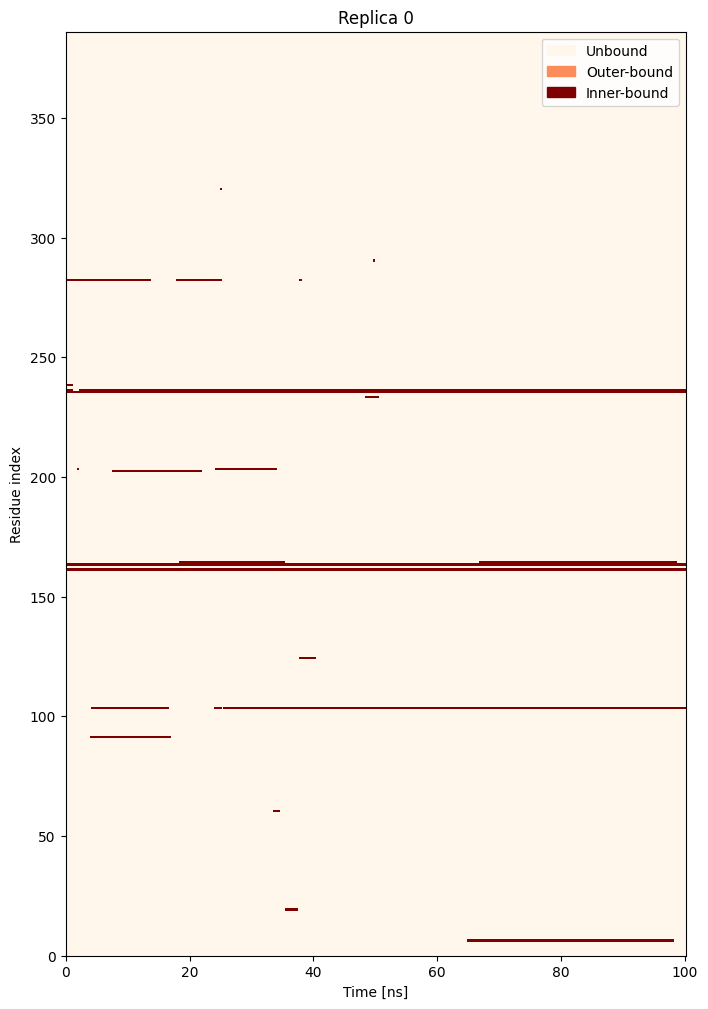

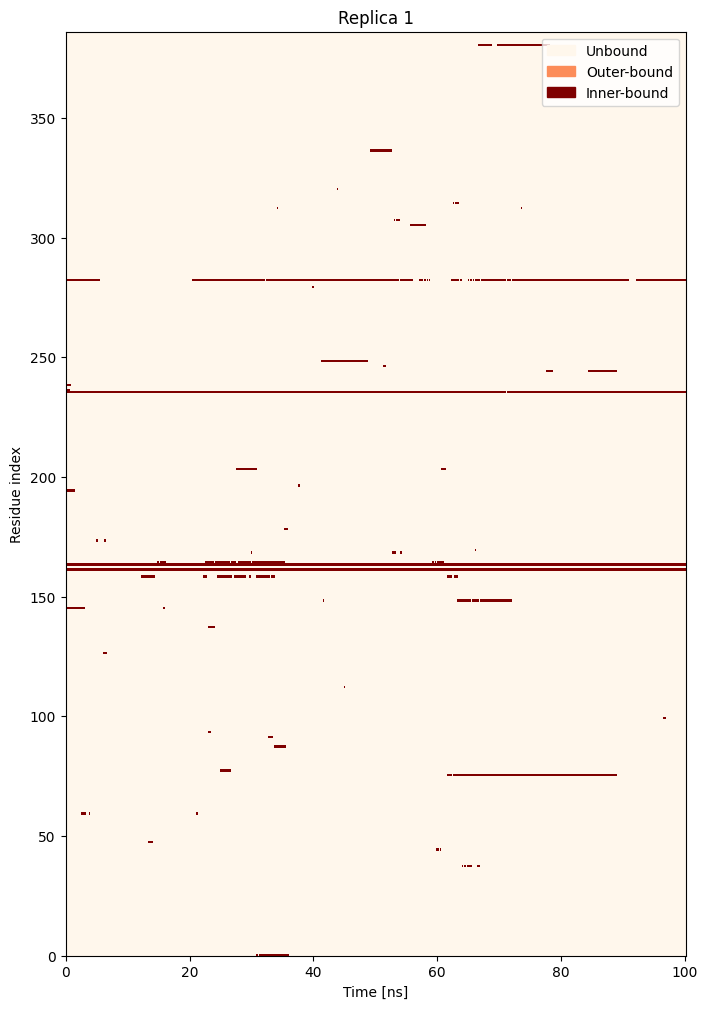

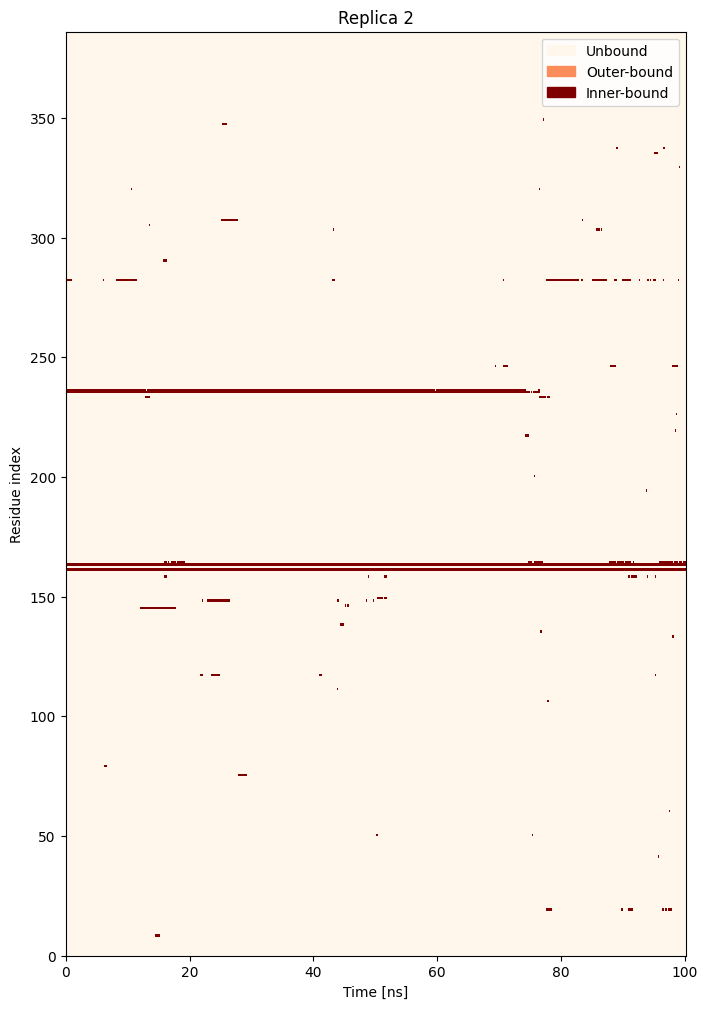

In [115]:
# New bound ions configurations found
for k in [0, 1, 2]:
    fig, ax = plt.subplots(figsize=(8, 12))
    # O1P or O2P
    is_bound_op = (d_op_mg_dmx[k, :, 1::2] < 0.25) * (d_op_mg_dmx[k, :, 2::2] < 0.25) * 1 
    #+ (d_op_mg_dmx[k, :, 1::2] < 0.42) * (d_op_mg_dmx[k, :, 2::2] < 0.42) * 1
    from matplotlib.patches import Patch
    cmap = plt.cm.OrRd
    custom_patches = [Patch(color=cmap(0.), label='Unbound'),
                    Patch(color=cmap(.5), label='Outer-bound'),
                    Patch(color=cmap(1.), label='Inner-bound')]
    ax.imshow(is_bound_op.T, origin='lower', extent=[0, len(is_bound_op)/10, 0, is_bound_op.shape[1]], aspect='auto', cmap=cmap, interpolation='none')
    ax.set_xlabel("Time [ns]")
    ax.set_ylabel(r"Residue index")
    ax.set_title(f"Replica {k}")
    ax.legend(handles=custom_patches)

Text(0, 0.5, '$\\min_t D_\\mathrm{Hamming}(\\vec{n}(t), \\vec{n}(t+τ))$')

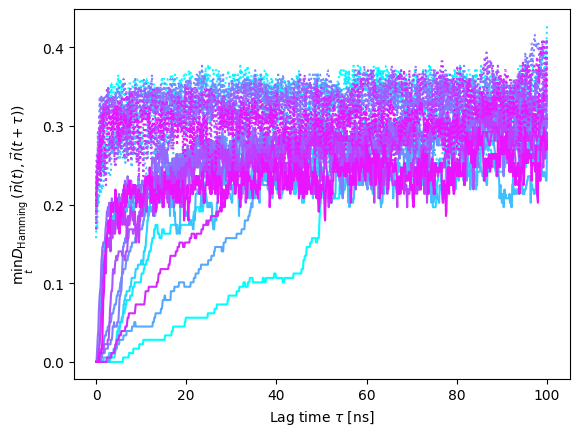

In [ ]:
#Decorrelation time per replica id

# Baseline: expected Hamming distance for a random permutation of M bound ions, where M is 

fig, ax = plt.subplots()
for k in range(12):
    is_bound_mg_dmx = d_mg_op_dmx[k, :, 1:] < 0.25
    is_bound_mg_dmx_rand = np.array([np.random.permutation(arr) for arr in is_bound_mg_dmx])
    N = len(is_bound_mg_dmx)
    c = []
    baseline = []
    for τ in range(N):
        # Hamming distance at lag τ, take the minimum value on the ensemble
        c.append((is_bound_mg_dmx[:N-τ] != is_bound_mg_dmx[τ:N]).mean(axis=-1).min())
        baseline.append((is_bound_mg_dmx[:N-τ] != is_bound_mg_dmx_rand[τ:N]).mean(axis=-1).min())

    ax.plot(np.arange(N)/10, c, color=plt.cm.cool(k / 12))
    ax.plot(np.arange(N)/10, baseline, color=plt.cm.cool(k / 12), ls='dotted')
ax.set_xlabel("Lag time $τ$ [ns]")
ax.set_ylabel(r"$\min_t D_\mathrm{Hamming}(\vec{n}(t), \vec{n}(t+τ))$")

Text(0, 0.5, '$ρ(d_\\mathrm{min})$')

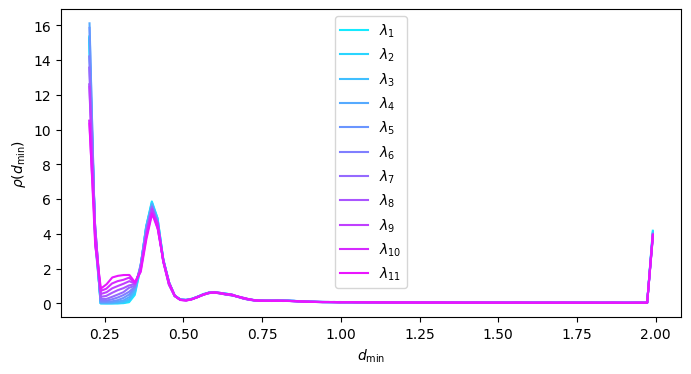

In [86]:
fig, ax = plt.subplots(figsize=(8, 4))
for i in range(1, 12):
    ρ_d, bins = np.histogram(d_mg_op[i, :, 1:].flatten(), bins=100, density=True)
    d_range = edges_to_range(bins)
    ax.plot(d_range, ρ_d, label=f'$λ_{{{i}}}$', color=plt.cm.cool(i/12.0))
ax.legend()
ax.set_xlabel('$d_\mathrm{min}$')
ax.set_ylabel('$ρ(d_\mathrm{min})$')

Text(0, 0.5, '$ρ(n)$')

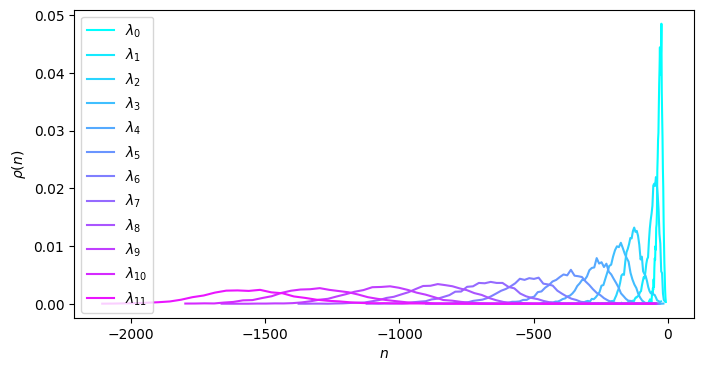

In [76]:
# CV distribution as a function of λ
fig, ax = plt.subplots(figsize=(8, 4))
for i in range(0, 12):
    ρ_u, bins = np.histogram(cv[i, :, 1], bins=50, density=True)
    u_range = edges_to_range(bins)
    ax.plot(u_range, ρ_u, label=f'$λ_{{{i}}}$', color=plt.cm.cool(i/12.0))
ax.legend()
ax.set_xlabel('$n$')
ax.set_ylabel('$ρ(n)$')